In [1]:
import numpy as np
import xarray as xr
import cartopy.crs
import cartopy.feature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.offsetbox import AnchoredText
from matplotlib.colors import LinearSegmentedColormap
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

In [2]:
colors_operability = [(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(255/256,127/256,80/256),(255/256,127/256,80/256),(255/256,255/256,51/256),(255/256,255/256,51/256),(0,204/256,0)]
colors_wavepower = [(0,204/256,0),(255/256,255/256,51/256),(255/256,255/256,51/256),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0),(1,0,0)]
name='my_list'
cwind ='#00a390'
cwave ='#eb7245'
cig ='#c41e79'
cwpow = '#77d3e9'
cmoperability = LinearSegmentedColormap.from_list(name, colors_operability, N=256)
cmwavepower = LinearSegmentedColormap.from_list(name, colors_wavepower, N=256)

In [3]:
data = pd.read_excel(r'c:\Users\wiegel\OneDrive - Stichting Deltares\Documents\model\output\output_run8_4560locs_d20_w138_s_2_i_005.xlsx')
bath = xr.open_dataset(r'c:\Users\wiegel\OneDrive - Stichting Deltares\Documents\input\ERA5_metOcean_bathy.nc')

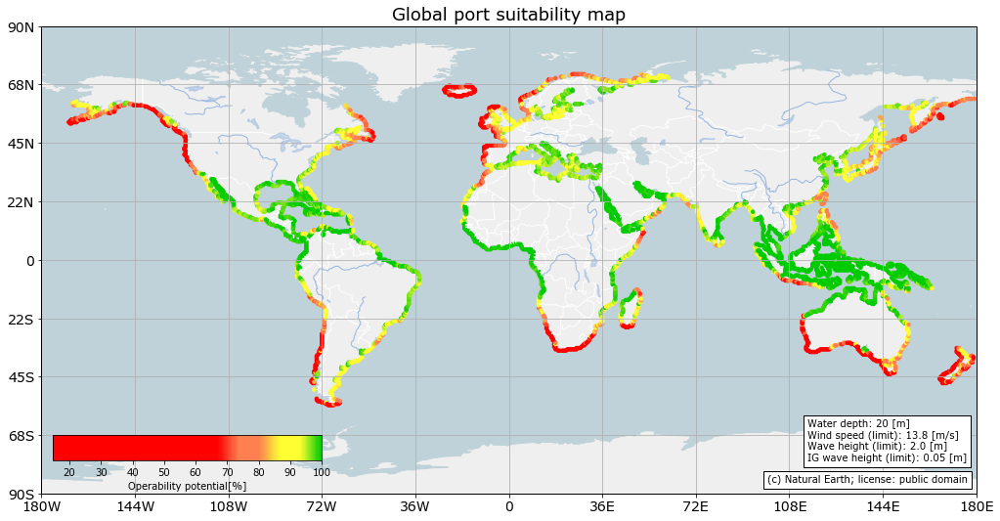

In [12]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(-180,180)
_ = ax.set_ylim(-90,90)
_ = ax.set_xticks(np.linspace(-180,180, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(-90,90, num=9), crs=cartopy.crs.PlateCarree())
pc = ax.scatter(data['lon'],data['lat'], c=data['operability'], s=12, cmap=cmoperability)#, cmap='RdYlGn_r')
       
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both', labelsize=14) #  which='both',
ax.text(115, -77.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
cax = plt.axes([0.01,0.103,0.239,0.04])
plt.colorbar(pc, ax=ax, cax=cax, label='Operability potential[%]', orientation='horizontal')
ax.set_title('Global port suitability map', fontsize=18)
plt.savefig('global_port_operability_map_4.png', dpi=300, bbox_inches='tight');

Text(0.5, 1.0, 'Port operability map (1979-01-01 - 2018-12-31)')

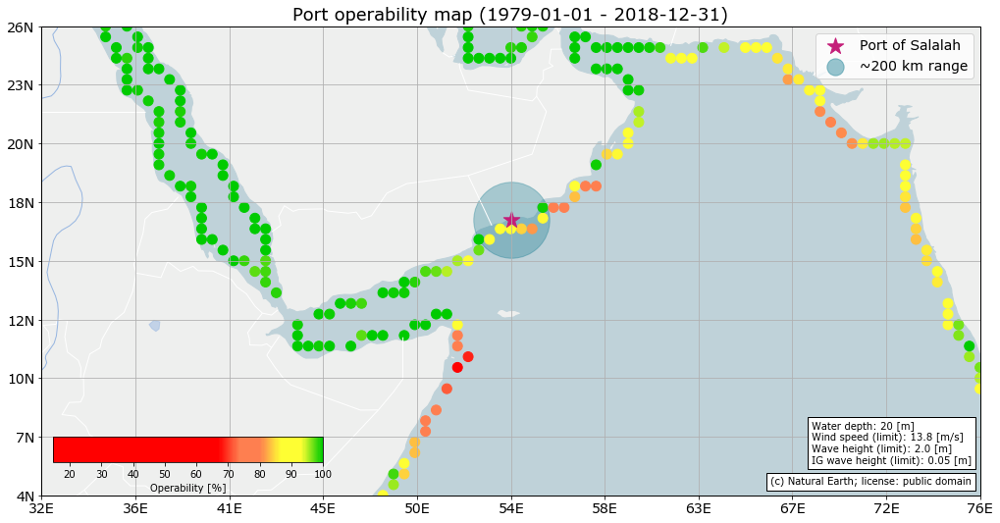

In [49]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(32,76)
_ = ax.set_ylim(4,26)
_ = ax.set_xticks(np.linspace(32,76, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(4,26, num=9), crs=cartopy.crs.PlateCarree())
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.scatter(54, 16.9, c='#007188', marker='o', s=6000, alpha=0.3)
pc = ax.scatter(data['lon'],data['lat'], c=data['operability'], s=100, cmap=cmoperability)#, cmap='RdYlGn_r')
ax.scatter(54, 16.9, c='#c41e79', marker='*', s=300, label='Port of Salalah')      
ax.scatter(72, 6, c='#007188', marker='o', s=300, alpha=0.4, label='~200 km range')      
#ax.contour(X, Y, depth2)

ax.tick_params(axis='both', labelsize=14) #  which='both',
ax.text(68.1, 5.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
cax = plt.axes([0.01,0.103,0.239,0.04])
plt.colorbar(pc, ax=ax, cax=cax, label='Operability [%]', orientation='horizontal')
ax.legend(fontsize=14)
ax.set_title('Port operability map (1979-01-01 - 2018-12-31)', fontsize=18)
#plt.savefig('global_port_operability_map_4_zoom.png', dpi=300, bbox_inches='tight');

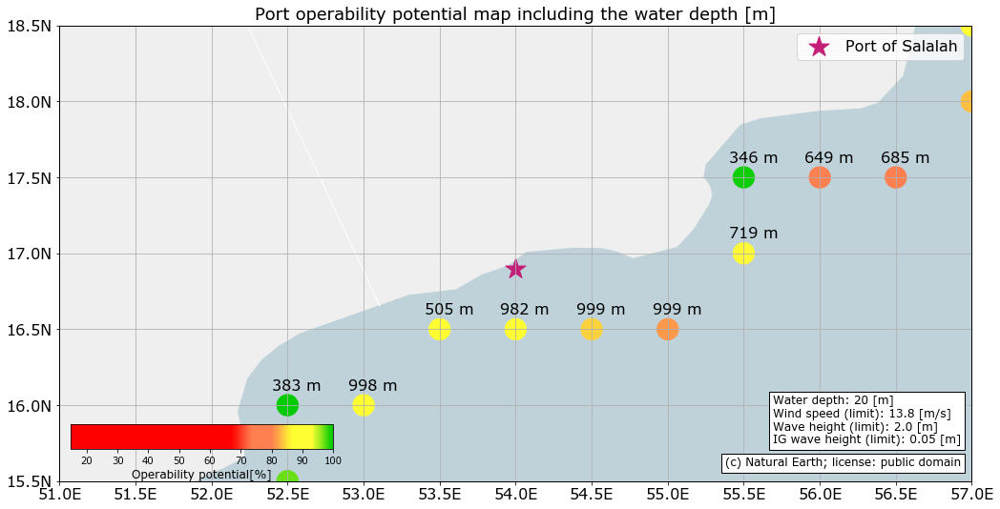

In [103]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(51,57)
_ = ax.set_ylim(15.5,18.5)
_ = ax.set_xticks(np.linspace(51,57, num=13), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(15.5,18.5, num=7), crs=cartopy.crs.PlateCarree())
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.1f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.1f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

pc = ax.scatter(data['lon'],data['lat'], c=data['operability'], s=500, cmap=cmoperability)#, cmap='RdYlGn_r')
ax.text(52.4,16.1,'383 m', fontsize=16)
ax.text(52.9,16.1,'998 m', fontsize=16)
ax.text(53.4,16.6,'505 m', fontsize=16)
ax.text(53.9,16.6,'982 m', fontsize=16)
ax.text(54.4,16.6,'999 m', fontsize=16)
ax.text(54.9,16.6,'999 m', fontsize=16)
ax.text(55.4,17.1,'719 m', fontsize=16)
ax.text(55.4,17.6,'346 m', fontsize=16)
ax.text(55.9,17.6,'649 m', fontsize=16)
ax.text(56.4,17.6,'685 m', fontsize=16)
ax.scatter(54, 16.9, c='#c41e79', marker='*', s=500, label='Port of Salalah')      

ax.tick_params(axis='both', labelsize=16) #  which='both',
ax.text(55.69, 15.75, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
ax.text(55.38, 15.6, '(c) Natural Earth; license: public domain', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
cax = plt.axes([0.01,0.103,0.239,0.04])
cbar = plt.colorbar(pc, ax=ax, cax=cax, label='Operability potential[%]', orientation='horizontal')
cbar.set_label('Operability potential[%]', size=12)
ax.legend(fontsize=16)
ax.set_title('Port operability potential map including the water depth [m]', fontsize=18)
plt.savefig('global_port_operability_map_4_zoom.png', dpi=300, bbox_inches='tight');

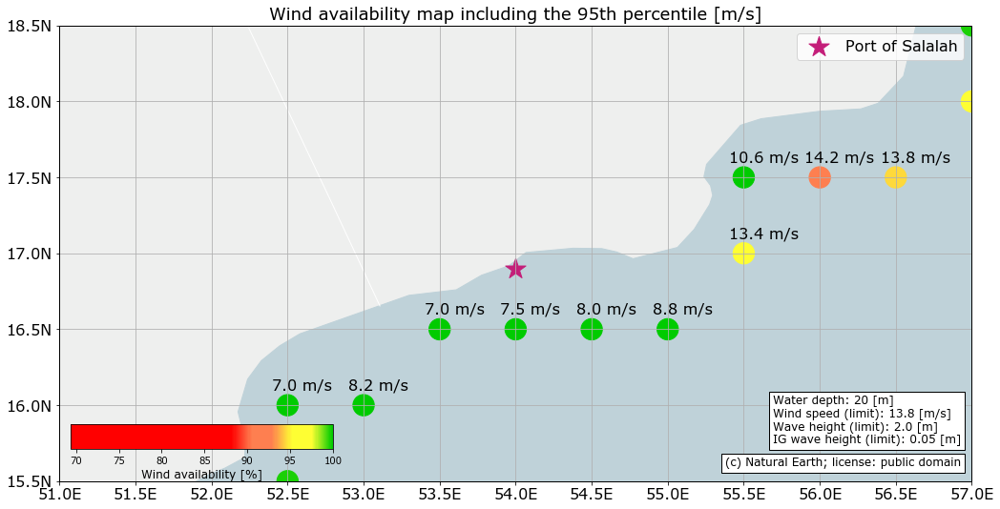

In [102]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(51,57)
_ = ax.set_ylim(15.5,18.5)
_ = ax.set_xticks(np.linspace(51,57, num=13), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(15.5,18.5, num=7), crs=cartopy.crs.PlateCarree())
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.1f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.1f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

pc = ax.scatter(data['lon'],data['lat'], c=data['windAvUp'], s=500, cmap=cmoperability)#, cmap='RdYlGn_r')
ax.text(52.4,16.1,'7.0 m/s', fontsize=16)
ax.text(52.9,16.1,'8.2 m/s', fontsize=16)
ax.text(53.4,16.6,'7.0 m/s', fontsize=16)
ax.text(53.9,16.6,'7.5 m/s', fontsize=16)
ax.text(54.4,16.6,'8.0 m/s', fontsize=16)
ax.text(54.9,16.6,'8.8 m/s', fontsize=16)
ax.text(55.4,17.1,'13.4 m/s', fontsize=16)
ax.text(55.4,17.6,'10.6 m/s', fontsize=16)
ax.text(55.9,17.6,'14.2 m/s', fontsize=16)
ax.text(56.4,17.6,'13.8 m/s', fontsize=16)
ax.scatter(54, 16.9, c='#c41e79', marker='*', s=500, label='Port of Salalah')      

ax.tick_params(axis='both', labelsize=16) #  which='both',
ax.text(55.69, 15.75, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
ax.text(55.38, 15.6, '(c) Natural Earth; license: public domain', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
cax = plt.axes([0.01,0.103,0.239,0.04])
cbar = plt.colorbar(pc, ax=ax, cax=cax, label='Wind availability[%]', orientation='horizontal')
cbar.set_label('Wind availability [%]', size=12)
ax.legend(fontsize=16)
ax.set_title('Wind availability map including the 95th percentile [m/s]', fontsize=18)
plt.savefig('global_port_operability_map_4_zoom_wind.png', dpi=300, bbox_inches='tight');

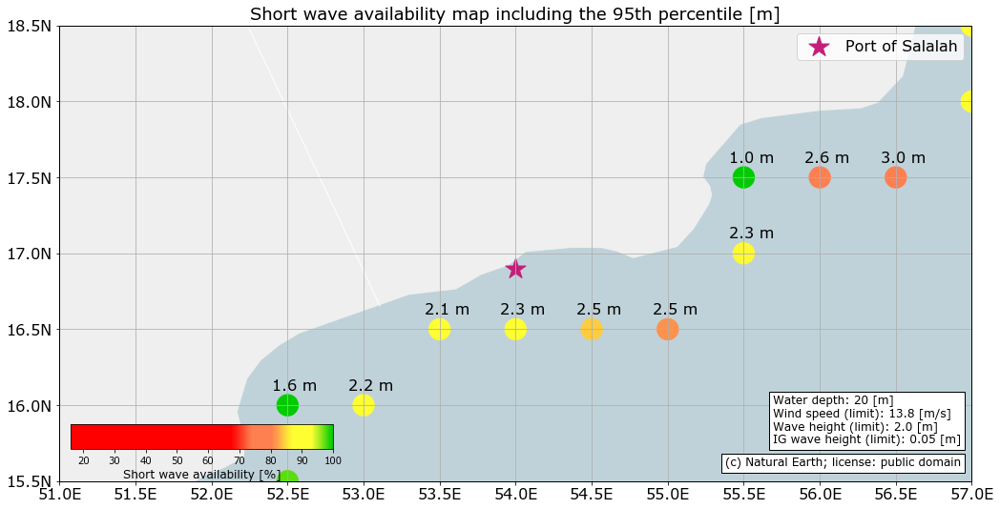

In [101]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(51,57)
_ = ax.set_ylim(15.5,18.5)
_ = ax.set_xticks(np.linspace(51,57, num=13), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(15.5,18.5, num=7), crs=cartopy.crs.PlateCarree())
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.1f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.1f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

pc = ax.scatter(data['lon'],data['lat'], c=data['swhAvUp'], s=500, cmap=cmoperability)#, cmap='RdYlGn_r')
ax.text(52.4,16.1,'1.6 m', fontsize=16)
ax.text(52.9,16.1,'2.2 m', fontsize=16)
ax.text(53.4,16.6,'2.1 m', fontsize=16)
ax.text(53.9,16.6,'2.3 m', fontsize=16)
ax.text(54.4,16.6,'2.5 m', fontsize=16)
ax.text(54.9,16.6,'2.5 m', fontsize=16)
ax.text(55.4,17.1,'2.3 m', fontsize=16)
ax.text(55.4,17.6,'1.0 m', fontsize=16)
ax.text(55.9,17.6,'2.6 m', fontsize=16)
ax.text(56.4,17.6,'3.0 m', fontsize=16)
ax.scatter(54, 16.9, c='#c41e79', marker='*', s=500, label='Port of Salalah')      

ax.tick_params(axis='both', labelsize=16) #  which='both',
ax.text(55.69, 15.75, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
ax.text(55.38, 15.6, '(c) Natural Earth; license: public domain', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
cax = plt.axes([0.01,0.103,0.239,0.04])
cbar = plt.colorbar(pc, ax=ax, cax=cax, label='Short wave availability[%]', orientation='horizontal')
cbar.set_label('Short wave availability [%]', size=12)
ax.legend(fontsize=16)
ax.set_title('Short wave availability map including the 95th percentile [m]', fontsize=18)
plt.savefig('global_port_operability_map_4_zoom_wave.png', dpi=300, bbox_inches='tight');

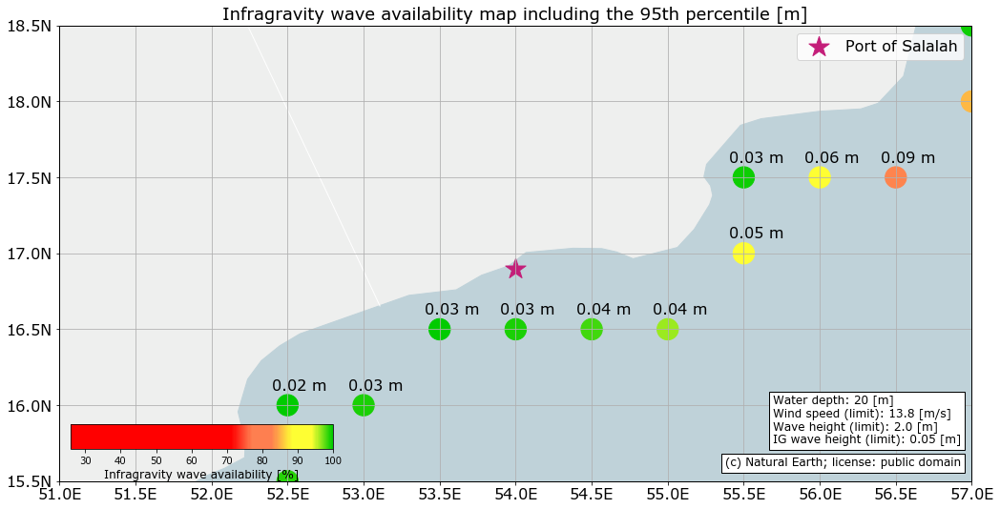

In [104]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(51,57)
_ = ax.set_ylim(15.5,18.5)
_ = ax.set_xticks(np.linspace(51,57, num=13), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(15.5,18.5, num=7), crs=cartopy.crs.PlateCarree())
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.1f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.1f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

pc = ax.scatter(data['lon'],data['lat'], c=data['igAvUp'], s=500, cmap=cmoperability)#, cmap='RdYlGn_r')
ax.text(52.4,16.1,'0.02 m', fontsize=16)
ax.text(52.9,16.1,'0.03 m', fontsize=16)
ax.text(53.4,16.6,'0.03 m', fontsize=16)
ax.text(53.9,16.6,'0.03 m', fontsize=16)
ax.text(54.4,16.6,'0.04 m', fontsize=16)
ax.text(54.9,16.6,'0.04 m', fontsize=16)
ax.text(55.4,17.1,'0.05 m', fontsize=16)
ax.text(55.4,17.6,'0.03 m', fontsize=16)
ax.text(55.9,17.6,'0.06 m', fontsize=16)
ax.text(56.4,17.6,'0.09 m', fontsize=16)
ax.scatter(54, 16.9, c='#c41e79', marker='*', s=500, label='Port of Salalah')      

ax.tick_params(axis='both', labelsize=16) #  which='both',
ax.text(55.69, 15.75, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
ax.text(55.38, 15.6, '(c) Natural Earth; license: public domain', bbox={'facecolor': 'white', 'alpha': 1}, fontsize=12)
cax = plt.axes([0.01,0.103,0.239,0.04])
cbar = plt.colorbar(pc, ax=ax, cax=cax, label='Infragravity wave availability[%]', orientation='horizontal')
cbar.set_label('Infragravity wave availability [%]', size=12)
ax.legend(fontsize=16)
ax.set_title('Infragravity wave availability map including the 95th percentile [m]', fontsize=18)
plt.savefig('global_port_operability_map_4_zoom_ig.png', dpi=300, bbox_inches='tight');

Text(69, 4.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]')

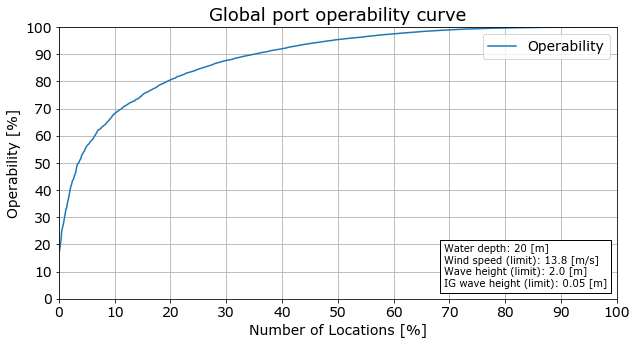

In [5]:
operability = data.operability.dropna().copy()
windOP = data.windAvUp.dropna().copy()
wavesOP = data.swhAvUp.dropna().copy()
igOP = data.igAvUp.dropna().copy()

x = np.arange(0.001,1.001,0.001)
tot_operability = operability.quantile(q=x)
wind_availability = windOP.quantile(q=x)
waves_availability = wavesOP.quantile(q=x)
infragravity_availability = igOP.quantile(q=x)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x*100, tot_operability, label='Operability')
#ax.plot(x*100, wind_availability, color=cwind, label='Wind')
#ax.plot(x*100, waves_availability, color=cwave, label='Short waves')
#ax.plot(x*100, infragravity_availability, color=cig, label='Infragravity waves')
ax.grid()
ax.set_xlim(0,100)
ax.set_ylim(0,100)
ax.set_title('Global port operability curve', fontsize=18)
ax.set_xlabel('Number of Locations [%]', size=14)
ax.set_ylabel('Operability [%]', size=14)
ax.tick_params(axis='both', labelsize=14)
ax.set_xticks(np.arange(0, 110, step=10));
ax.set_yticks(np.arange(0, 110, step=10));
ax.legend(loc='upper right',  fontsize=14, markerscale=1)
ax.text(69, 4.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})

#plt.savefig('global_port_operability_curve.png', dpi=300, bbox_inches='tight');

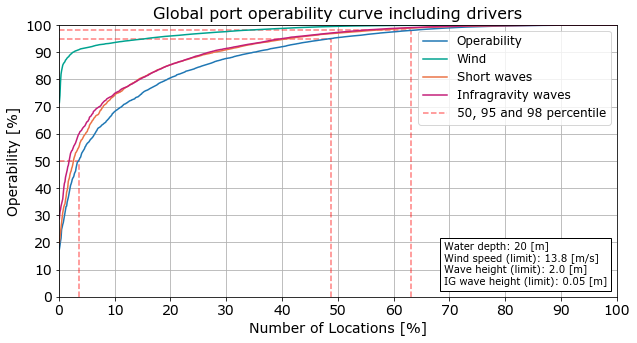

In [22]:
operability = data.operability.dropna().copy()
operability1 = np.sort(operability)
x = np.arange(0.001,1.001,0.001)
tot_operability = operability.quantile(q=x)
p50 = np.quantile(operability,0.5)
p95 = np.quantile(operability,0.95)
p98 = np.quantile(operability,0.98)
windOP = data.windAvUp.dropna().copy()
wavesOP = data.swhAvUp.dropna().copy()
igOP = data.igAvUp.dropna().copy()
wind_availability = windOP.quantile(q=x)
waves_availability = wavesOP.quantile(q=x)
infragravity_availability = igOP.quantile(q=x)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x*100, tot_operability, label='Operability')
plt.hlines(98,0,find_nearest(operability1,98)/len(operability)*100,'r',linestyle='dashed', alpha=0.5, label='50, 95 and 98 percentile')
plt.hlines(95,0,find_nearest(operability1,95)/len(operability)*100,'r',linestyle='dashed', alpha=0.5)
plt.hlines(50,0,find_nearest(operability1,50)/len(operability)*100,'r',linestyle='dashed', alpha=0.5)
plt.vlines(find_nearest(operability1,98)/len(operability)*100,0,98,'r',linestyle='dashed', alpha=0.5)
plt.vlines(find_nearest(operability1,95)/len(operability)*100,0,95,'r',linestyle='dashed', alpha=0.5)
plt.vlines(find_nearest(operability1,50)/len(operability)*100,0,50,'r',linestyle='dashed', alpha=0.5)
ax.plot(x*100, wind_availability, color=cwind, label='Wind')
ax.plot(x*100, waves_availability, color=cwave, label='Short waves')
ax.plot(x*100, infragravity_availability, color=cig, label='Infragravity waves')

ax.grid()
ax.set_xlim(0,100)
ax.set_ylim(0,100)
ax.set_title('Global port operability curve including drivers', fontsize=16)
ax.set_xlabel('Number of Locations [%]', size=14)
ax.set_ylabel('Operability [%]', size=14)
ax.tick_params(axis='both', labelsize=14)
ax.set_xticks(np.arange(0, 110, step=10));
ax.set_yticks(np.arange(0, 110, step=10));
ax.legend(loc='upper right',  fontsize=12, markerscale=1)
ax.text(69, 4.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})

plt.savefig('global_port_operability_curve_with_driversandpercentiles.png', dpi=300, bbox_inches='tight');

Text(69, 4.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]')

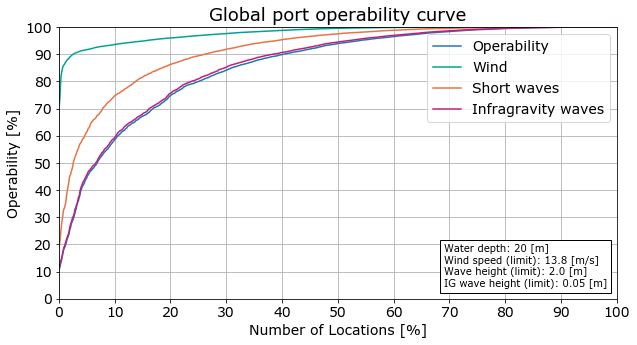

In [6]:
operability = data.operability.dropna().copy()
windOP = data.windAvUp.dropna().copy()
wavesOP = data.swhAvUp.dropna().copy()
igOP = data.igAvUp.dropna().copy()

x = np.arange(0.001,1.001,0.001)
tot_operability = operability.quantile(q=x)
wind_availability = windOP.quantile(q=x)
waves_availability = wavesOP.quantile(q=x)
infragravity_availability = igOP.quantile(q=x)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x*100, tot_operability, label='Operability')
ax.plot(x*100, wind_availability, color=cwind, label='Wind')
ax.plot(x*100, waves_availability, color=cwave, label='Short waves')
ax.plot(x*100, infragravity_availability, color=cig, label='Infragravity waves')
ax.grid()
ax.set_xlim(0,100)
ax.set_ylim(0,100)
ax.set_title('Global port operability curve', fontsize=18)
ax.set_xlabel('Number of Locations [%]', size=14)
ax.set_ylabel('Operability [%]', size=14)
ax.tick_params(axis='both', labelsize=14)
ax.set_xticks(np.arange(0, 110, step=10));
ax.set_yticks(np.arange(0, 110, step=10));
ax.legend(loc='upper right',  fontsize=14, markerscale=1)
ax.text(69, 4.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})

#plt.savefig('global_port_operability_curve_includ_drivers.png', dpi=300, bbox_inches='tight');

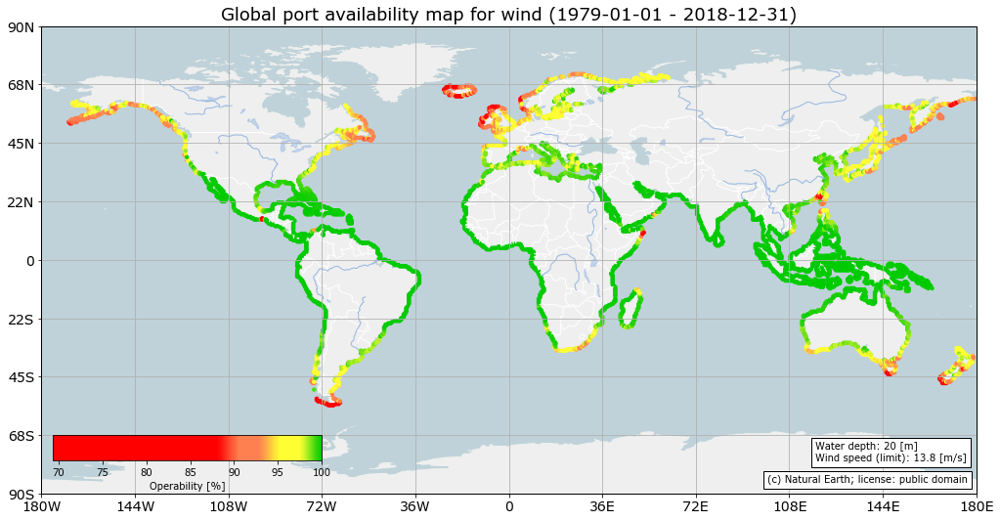

In [67]:
y = 'windAvUp'
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(-180,180)
_ = ax.set_ylim(-90,90)
_ = ax.set_xticks(np.linspace(-180,180, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(-90,90, num=9), crs=cartopy.crs.PlateCarree())
pc = ax.scatter(data['lon'],data['lat'], c=data[y], s=12, cmap=cmoperability)#, cmap='RdYlGn_r')
       
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both', labelsize=14) #  which='both',
ax.text(118, -77.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
cax = plt.axes([0.01,0.103,0.239,0.04])
plt.colorbar(pc, ax=ax, cax=cax, label='Operability [%]', orientation='horizontal')
ax.set_title('Global port availability map for wind (1979-01-01 - 2018-12-31)', fontsize=18)
plt.savefig('global_port_availability_map_wind_speed.png', dpi=300, bbox_inches='tight');

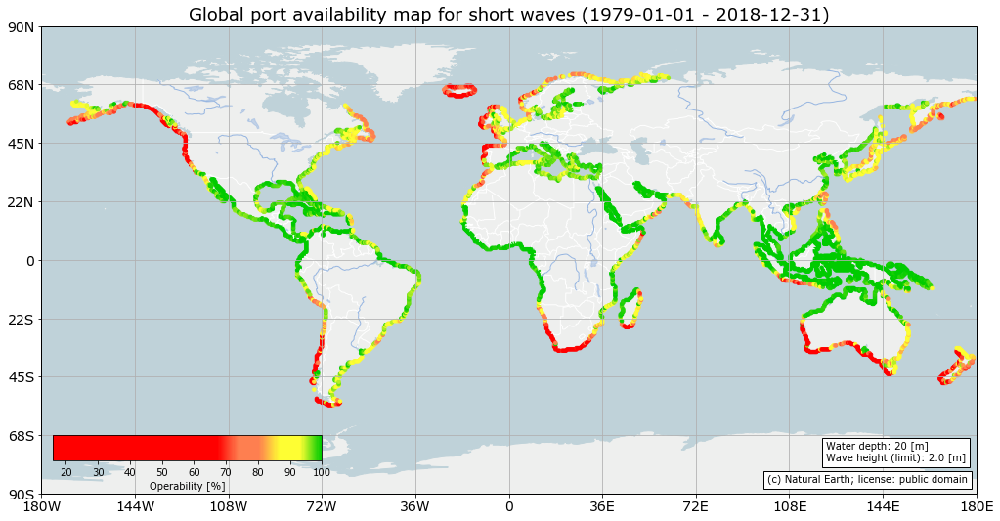

In [65]:
y = 'swhAvUp'
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(-180,180)
_ = ax.set_ylim(-90,90)
_ = ax.set_xticks(np.linspace(-180,180, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(-90,90, num=9), crs=cartopy.crs.PlateCarree())
pc = ax.scatter(data['lon'],data['lat'], c=data[y], s=12, cmap=cmoperability)#, cmap='RdYlGn_r')
       
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both', labelsize=14) #  which='both',
ax.text(122, -77.5, 'Water depth: 20 [m] \nWave height (limit): 2.0 [m]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
cax = plt.axes([0.01,0.103,0.239,0.04])
plt.colorbar(pc, ax=ax, cax=cax, label='Operability [%]', orientation='horizontal')
ax.set_title('Global port availability map for short waves (1979-01-01 - 2018-12-31)', fontsize=18)
plt.savefig('global_port_availability_map_wave_height.png', dpi=300, bbox_inches='tight');

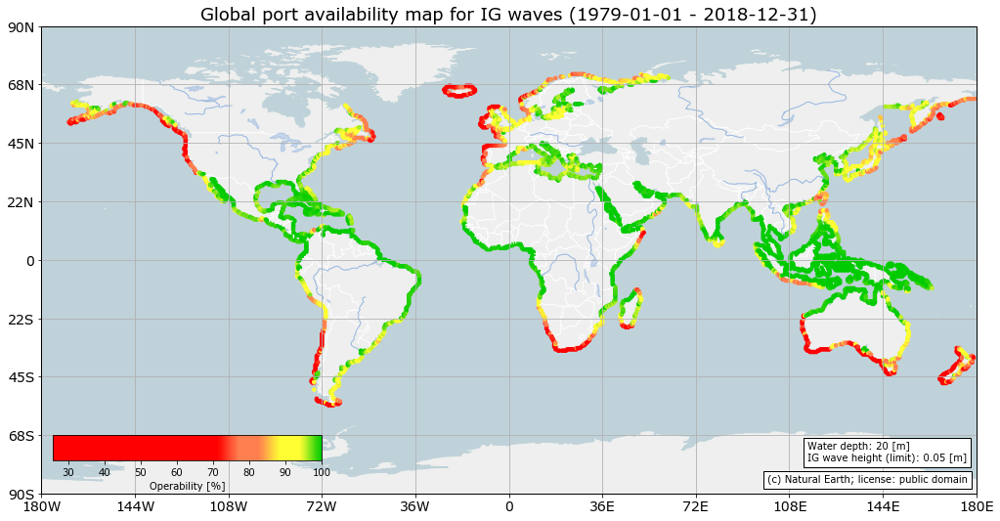

In [61]:
y = 'igAvUp'
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(-180,180)
_ = ax.set_ylim(-90,90)
_ = ax.set_xticks(np.linspace(-180,180, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(-90,90, num=9), crs=cartopy.crs.PlateCarree())
pc = ax.scatter(data['lon'],data['lat'], c=data[y], s=12, cmap=cmoperability)#, cmap='RdYlGn_r')
       
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both', labelsize=14) #  which='both',
ax.text(115, -77.5, 'Water depth: 20 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
cax = plt.axes([0.01,0.103,0.239,0.04])
plt.colorbar(pc, ax=ax, cax=cax, label='Operability [%]', orientation='horizontal')
ax.set_title('Global port availability map for IG waves (1979-01-01 - 2018-12-31)', fontsize=18)
plt.savefig('global_port_availability_map_ig_wave.png', dpi=300, bbox_inches='tight');

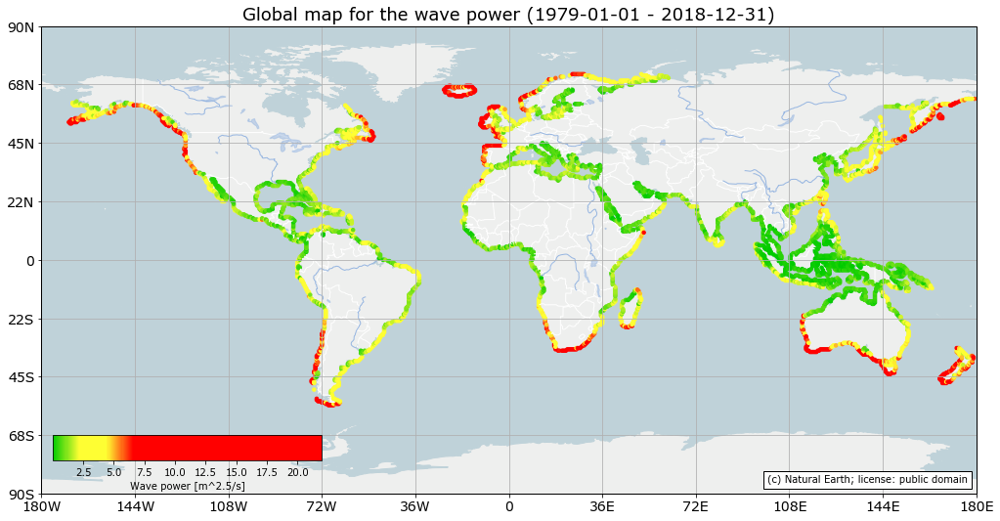

In [78]:
y = 'wavePo'
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(-180,180)
_ = ax.set_ylim(-90,90)
_ = ax.set_xticks(np.linspace(-180,180, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(-90,90, num=9), crs=cartopy.crs.PlateCarree())
pc = ax.scatter(data['lon'],data['lat'], c=data[y], s=12, cmap=cmwavepower)#, cmap='RdYlGn_r')
       
ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both', labelsize=14) #  which='both',
#ax.text(115, -77.5, 'Water depth: 20 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
cax = plt.axes([0.01,0.103,0.239,0.04])
plt.colorbar(pc, ax=ax, cax=cax, label='Wave power [m^2.5/s]', orientation='horizontal')
ax.set_title('Global map for the wave power (1979-01-01 - 2018-12-31)', fontsize=18)
plt.savefig('global_port_availability_wave_power.png', dpi=300, bbox_inches='tight');

In [10]:
driver1 = data[data['main_driver']==1]
driver2 = data[data['main_driver']==2]
driver25 = data[data['main_driver']==2.5]
driver3 = data[data['main_driver']==3]

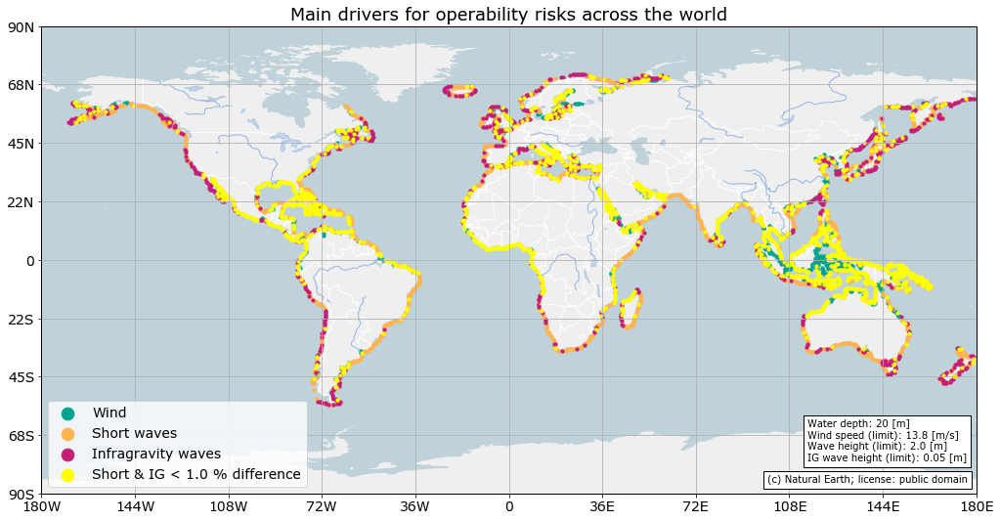

In [11]:
plt.figure(figsize=(16, 9), facecolor='white')
ax = plt.axes([0, 0.02, 0.83, 0.8],projection=cartopy.crs.PlateCarree())
ax.grid()
_ = ax.set_xlim(-180,180)
_ = ax.set_ylim(-90,90)
_ = ax.set_xticks(np.linspace(-180,180, num=11), crs=cartopy.crs.PlateCarree())
_ = ax.set_yticks(np.linspace(-90,90, num=9), crs=cartopy.crs.PlateCarree())
#pc = ax.scatter(driver0['lon'],driver0['lat'],c='#00CC00', s=10, marker='o', label='Operability > 95 %') #c=driver0['operability'], cmap=cmoperability
pc = ax.scatter(driver1['lon'],driver1['lat'],c=cwind, s=10, marker='o', label='Wind') #c=driver1['operability'], cmap=cmoperability
pc = ax.scatter(driver2['lon'],driver2['lat'], c='#FFB450', s=10, marker='o', label='Short waves') #c=driver2['operability'], cmap=cmoperability
pc = ax.scatter(driver3['lon'],driver3['lat'], c=cig, s=10, marker='o', label='Infragravity waves') #c=driver3['operability'], cmap=cmoperability
pc = ax.scatter(driver25['lon'],driver25['lat'], c='yellow', s=10, marker='o', label='Short & IG < 1.0 % difference') #c=driver2['operability'], cmap=cmoperability

ax.add_feature(cartopy.feature.LAND.with_scale('50m'),facecolor='#EEEFEE')
ax.add_feature(cartopy.feature.OCEAN.with_scale('50m'),facecolor='#bfd2d9')
#ax.add_feature(cartopy.feature.COASTLINE.with_scale('50m'))
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white')
ax.add_feature(cartopy.feature.LAKES, alpha=0.5)
ax.add_feature(cartopy.feature.RIVERS)

lon_formatter = LongitudeFormatter(number_format='.0f',degree_symbol='',dateline_direction_label=True)
lat_formatter = LatitudeFormatter(number_format='.0f', degree_symbol='')
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both', labelsize=14) #  which='both',
ax.text(115, -77.5, 'Water depth: 20 [m] \nWind speed (limit): 13.8 [m/s] \nWave height (limit): 2.0 [m] \nIG wave height (limit): 0.05 [m]', bbox={'facecolor': 'white', 'alpha': 1})
text = AnchoredText(('(c) Natural Earth; license: public domain'), loc=4, frameon=True)
ax.add_artist(text)
ax.legend(loc='lower left', fontsize=14, markerscale=4)
#cax = plt.axes([0.01,0.103,0.239,0.04])
#plt.colorbar(pc, ax=ax, cax=cax, label='Operability [%]', orientation='horizontal')
ax.set_title('Main drivers for operability risks across the world', fontsize=18)
plt.savefig('global_port_operability_main_cause_2.png', dpi=300, bbox_inches='tight');

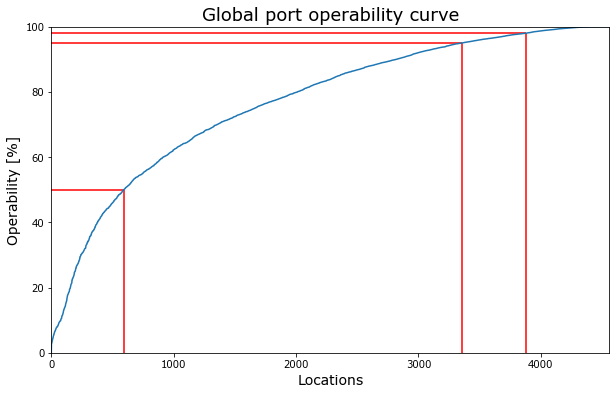

In [333]:
operability = np.sort(data7.operability)
operability[-1] = 0
p50 = np.quantile(operability,0.5)
p95 = np.quantile(operability,0.95)
p98 = np.quantile(operability,0.98)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(np.sort(data7.operability), label='Operability')
plt.hlines(98,0,find_nearest(operability,98),'r')
plt.hlines(95,0,find_nearest(operability,95),'r')
plt.hlines(50,0,find_nearest(operability,50),'r')
plt.vlines(find_nearest(operability,98),0,98,'r')
plt.vlines(find_nearest(operability,95),0,95,'r')
plt.vlines(find_nearest(operability,50),0,50,'r')
ax.set_ylabel('Operability [%]', size=14)
ax.set_xlabel('Locations', size=14)
ax.set_title('Global port operability curve', fontsize=18)
ax.set_xlim(0,4560)
ax.set_ylim(0,100)
#ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10),fancybox=True, ncol=1, fontsize=14)
plt.savefig('global_port_operability_curve.png', dpi=300, bbox_inches='tight');

## Approximate recovery of the scatter points in cell 4

The next cell runs independently of the spreadsheet and earlier cells. It reads the **saved PNG output of cell 4**, selects pixels matching its colormap, and estimates visible marker centres using distance-transform peaks with a two-pixel minimum separation. A second pass adds explicitly labelled **overlap estimates** in unresolved marker interiors at least two pixels from their edges and more than 2.5 pixels from existing detections. Hidden points cannot be recovered, and touching markers may be merged or split incorrectly. These are approximate detections, not original records.

The PNG is 1023 x 533 pixels. Its manually checked map frame is x = 42..999, y = 27..505, corresponding to longitude -180..180 and latitude 90..-90 (Plate Carree). One pixel is approximately 0.38 degrees; merged markers can introduce larger errors. The colour bar is excluded. The seven colour classes describe flat colours and transitions in the original colormap, **not recovered operability percentages**. A broad range of original values shares the same red colour.

`recovered_points` contains coordinates, colour classes, matched colours, source-pixel positions, and the detection method. The inline Folium map includes class toggles and an optional **Original scatter pixels (reference)** layer, reprojected to Web Mercator for comparison. The world background uses the adjacent `recovery-world-background.geojson` file ([Natural Earth, public domain](https://www.naturalearthdata.com/about/terms-of-use/)), embedded directly in the map: no tile service or API key is needed. Leaflet assets still require internet access. No HTML file is written. The final export cell saves the approximate point data as `recovered-port-operability.geojson`, including colour classes and detection methods. Keep the saved output of cell 4 intact; do not rerun its raw-data-loading cells.

/opt/anaconda3/envs/OpenTNSim/lib/python3.13/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


2,023 approximate visible marker centres recovered.
Including 169 inferred overlap estimates.
94.6% of selected marker pixels lie within 2.5 pixels of a detection.
This is image coverage, not the fraction of original records recovered.
Pixel scale: 0.376 degrees longitude, 0.377 degrees latitude.


,points
color_class,
Red,171
Red-coral,178
Coral,72
Coral-yellow,275
Yellow,203
Yellow-green,806
Green,318



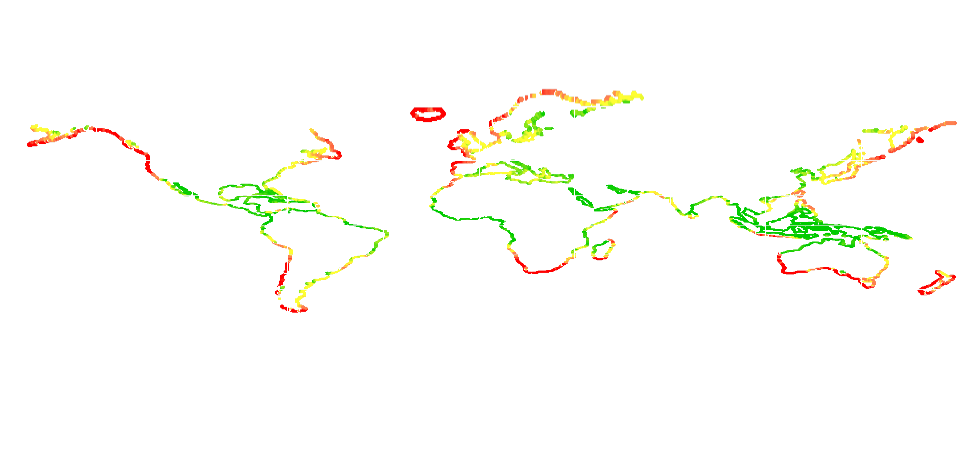

In [1]:
import base64
import io
import json
from pathlib import Path

import folium
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, to_hex
from PIL import Image
from scipy import ndimage
from scipy.spatial import cKDTree

recovery_root = Path.cwd().parent if Path.cwd().name == 'archive' else Path.cwd()
notebook_path = recovery_root / 'archive' / 'output-global.ipynb'
notebook_document = json.loads(notebook_path.read_text(encoding='utf-8'))
png_outputs = [
    output['data']['image/png']
    for output in notebook_document['cells'][3].get('outputs', [])
    if 'image/png' in output.get('data', {})
]
if len(png_outputs) != 1:
    raise ValueError('Expected one saved PNG in cell 4; restore its original output.')
png_bytes = base64.b64decode(''.join(png_outputs[0]))
source_rgb = np.array(Image.open(io.BytesIO(png_bytes)).convert('RGB'))
if source_rgb.shape != (533, 1023, 3):
    raise ValueError('The source image changed; recalibrate the map frame and colour-bar mask.')

# These bounds are calibrated to the saved PNG, not the original figure size.
left, right, top, bottom = 42, 999, 27, 505
pixel_lon = 360 / (right - left)
pixel_lat = 180 / (bottom - top)
recovery_colours = (
    [(1, 0, 0)] * 9
    + [(255 / 256, 127 / 256, 80 / 256)] * 2
    + [(255 / 256, 255 / 256, 51 / 256)] * 2
    + [(0, 204 / 256, 0)]
)
recovery_cmap = LinearSegmentedColormap.from_list('recovery', recovery_colours, N=256)
palette_rgb = np.round(recovery_cmap(np.arange(256))[:, :3] * 255).astype(np.uint8)
colour_error, palette_index = cKDTree(palette_rgb).query(source_rgb.reshape(-1, 3))
colour_error = colour_error.reshape(source_rgb.shape[:2])
palette_index = palette_index.reshape(source_rgb.shape[:2])
marker_mask = colour_error <= 8
map_interior = np.zeros(marker_mask.shape, dtype=bool)
map_interior[top + 1:bottom, left + 1:right] = True
marker_mask &= map_interior
marker_mask[444:474, 53:331] = False  # Exclude the colour bar and its antialiased edges.


def detect_marker_centres(mask):
    distance = ndimage.distance_transform_edt(mask)
    peaks = mask & (distance == ndimage.maximum_filter(distance, size=3))
    candidates = np.argwhere(peaks)
    if not len(candidates):
        raise ValueError('No marker centres detected; check the saved image and palette.')
    order = np.argsort(-distance[tuple(candidates.T)], kind='stable')
    blocked = np.zeros(mask.shape, dtype=bool)
    centres = []
    for y, x in candidates[order]:
        if blocked[y, x]:
            continue
        centres.append((y, x))
        y0, y1 = max(0, y - 2), min(mask.shape[0], y + 3)
        x0, x1 = max(0, x - 2), min(mask.shape[1], x + 3)
        yy, xx = np.ogrid[y0:y1, x0:x1]
        blocked[y0:y1, x0:x1] |= (yy - y) ** 2 + (xx - x) ** 2 < 2 ** 2
    peak_count = len(centres)
    seed_mask = np.zeros(mask.shape, dtype=bool)
    seed_mask[tuple(np.array(centres).T)] = True
    covered = ndimage.distance_transform_edt(~seed_mask) <= 2.5
    residual = np.argwhere(mask & ~covered & (distance >= 2))
    for y, x in residual[np.argsort(-distance[tuple(residual.T)], kind='stable')]:
        if covered[y, x]:
            continue
        centres.append((y, x))
        y0, y1 = max(0, y - 3), min(mask.shape[0], y + 4)
        x0, x1 = max(0, x - 3), min(mask.shape[1], x + 4)
        yy, xx = np.ogrid[y0:y1, x0:x1]
        covered[y0:y1, x0:x1] |= (yy - y) ** 2 + (xx - x) ** 2 <= 2.5 ** 2
    centres = np.array(centres, dtype=int)
    methods = np.where(np.arange(len(centres)) < peak_count, 'distance peak', 'overlap estimate')
    order = np.lexsort((centres[:, 1], centres[:, 0]))
    return centres[order], methods[order]


centres_yx, detection_methods = detect_marker_centres(marker_mask)
centre_y, centre_x = centres_yx.T
centre_palette = palette_index[centre_y, centre_x]
class_names = ['Red', 'Red-coral', 'Coral', 'Coral-yellow', 'Yellow', 'Yellow-green', 'Green']
# Boundaries separate the repeated anchors and transitions in cell 2's colormap.
class_index = np.searchsorted([157, 177, 197, 216, 236, 255], centre_palette, side='right')
recovered_points = pd.DataFrame({
    'point_id': np.arange(1, len(centres_yx) + 1),
    'lon': -180 + (centre_x - left) * pixel_lon,
    'lat': 90 - (centre_y - top) * pixel_lat,
    'color_class': np.array(class_names)[class_index],
    'color_hex': [to_hex(palette_rgb[i] / 255) for i in centre_palette],
    'pixel_x': centre_x,
    'pixel_y': centre_y,
    'detection_method': detection_methods,
})
nearest_distance, _ = cKDTree(centres_yx).query(np.argwhere(marker_mask))
pixel_coverage = np.mean(nearest_distance <= 2.5)
print(f'{len(recovered_points):,} approximate visible marker centres recovered.')
print(f"Including {(detection_methods == 'overlap estimate').sum():,} inferred overlap estimates.")
print(f'{pixel_coverage:.1%} of selected marker pixels lie within 2.5 pixels of a detection.')
print('This is image coverage, not the fraction of original records recovered.')
print(f'Pixel scale: {pixel_lon:.3f} degrees longitude, {pixel_lat:.3f} degrees latitude.')
display(recovered_points.groupby('color_class').size().reindex(class_names, fill_value=0).rename('points').to_frame())

world_background = json.loads(
    notebook_path.with_name('recovery-world-background.geojson').read_text(encoding='utf-8')
)
recovery_map = folium.Map(location=[12, 0], zoom_start=2, tiles=None, prefer_canvas=True)
recovery_map.get_root().header.add_child(folium.Element(
    '<style>.leaflet-container {background: #bfd2d9 !important;}</style>'
))
folium.GeoJson(
    world_background, name='World background (Natural Earth)', overlay=False,
    attribution='Natural Earth (public domain)', interactive=False,
    style_function=lambda feature: {
        'fillColor': '#eeefee', 'fillOpacity': 1, 'color': '#ffffff', 'weight': 0.5,
    },
).add_to(recovery_map)
for colour_class in class_names:
    points_in_class = recovered_points.loc[recovered_points['color_class'] == colour_class]
    layer = folium.FeatureGroup(name=f'{colour_class}: {len(points_in_class):,} points')
    for point in points_in_class.itertuples(index=False):
        folium.CircleMarker(
            location=[point.lat, point.lon], radius=2.5, weight=0,
            color=point.color_hex, fill=True, fill_color=point.color_hex, fill_opacity=1,
            tooltip=f'#{point.point_id}: {point.color_class}',
            popup=(f'Approximate detection #{point.point_id}<br>Class: {point.color_class}'
                   f'<br>Lon: {point.lon:.3f}, lat: {point.lat:.3f}'
                   f'<br>Source pixel: ({point.pixel_x}, {point.pixel_y})'
                   f'<br>Method: {point.detection_method}'
                   '<br>Operability value not recoverable from this colour alone.'),
        ).add_to(layer)
    layer.add_to(recovery_map)

# Crop away the poles before reprojecting the Plate Carree reference image.
overlay_top, overlay_bottom = top + 14, bottom - 14
source_rgba = np.dstack((source_rgb, marker_mask.astype(np.uint8) * 255))
folium.raster_layers.ImageOverlay(
    image=source_rgba[overlay_top:overlay_bottom, left:right],
    bounds=[[90 - (overlay_bottom - top) * pixel_lat, -180],
            [90 - (overlay_top - top) * pixel_lat, 180]],
    origin='upper', mercator_project=True,
    name='Original scatter pixels (reference)', opacity=0.85, show=False,
).add_to(recovery_map)
folium.LayerControl(collapsed=True).add_to(recovery_map)
recovery_map

In [2]:
geojson_path = notebook_path.with_name('recovered-port-operability.geojson')
recovered_geojson = {
    'type': 'FeatureCollection',
    'name': 'recovered_port_operability',
    'description': (
        'Approximate points digitized from the saved scatter image in cell 4 of '
        'output-global.ipynb, as displayed on the Folium recovery map. Colours '
        'are visual classes, not exact operability values. Hidden or overlapping '
        'original records cannot be uniquely recovered.'
    ),
    'features': [
        {
            'type': 'Feature',
            'id': row['point_id'],
            'geometry': {'type': 'Point', 'coordinates': [row['lon'], row['lat']]},
            'properties': {
                key: value for key, value in row.items() if key not in ('lon', 'lat')
            },
        }
        for row in recovered_points.to_dict(orient='records')
    ],
}
geojson_path.write_text(
    json.dumps(recovered_geojson, indent=2, allow_nan=False) + '\n', encoding='utf-8'
)
print(f'Saved {len(recovered_geojson["features"]):,} recovered points to {geojson_path.resolve()}')

Saved 2,023 recovered points to /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/recovered-port-operability.geojson


## Regenerated offshore ERA5 positions - markers only

This independent cell creates new positions from coastline geometry, **not from individual recovered marker centres**. It follows the native 0.5-degree ERA5 grid and the paper's 0.1-0.8 degree offshore band ([section 2.4](literature/jmse-09-00695-v2.pdf)). Coastline vertices are merged into continuous tracks, generalized by 0.1 degrees to avoid following sub-grid detail, and sampled at approximately **55.6 km** intervals (0.5 degrees of latitude). Eligible wet ERA5 cells are assigned to their nearest track anchor; at most one cell is retained per anchor. This avoids selecting parallel rows along a single coast. Native-grid snapping means the final spacing cannot be exactly constant; opposite shores of islands or straits can legitimately have separate rows.

**Coverage:** both anchors and grid cells must lie within 150 km of a recovered point from the original figure. Recovered positions define only an approximate coverage mask; their colours and values are not transferred. Greenland and Antarctica, including a 0.8-degree offshore margin, are explicitly excluded. Very short coastline fragments and small island rings are omitted. These are transparent approximations of the unavailable manual exclusions, not an exact recovery of the original 4,560 locations.

The plot below contains **only the new position markers and a plain world background**. CSV, GeoJSON and settings are saved under `data/processed/`. Only static ERA5 bathymetry and coastline geometry are needed; no hourly metocean data is requested. Run with the reproduction environment described in [README](README.md). No HTML file is saved.

In [1]:
import json
from pathlib import Path

import folium
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.geometry import shape
import sys
REPOSITORY_ROOT = Path.cwd().parent if Path.cwd().name == 'archive' else Path.cwd()
sys.path.insert(0, str(REPOSITORY_ROOT))
import port_operability as coastal_model

coastal_paths = coastal_model.data_directories(REPOSITORY_ROOT / 'data')
coastal_settings = {'spacing_km': 55.6, 'coverage_radius_km': 150, 'simplify_degrees': 0.1}
coastal_background = json.loads((REPOSITORY_ROOT / 'archive' / 'recovery-world-background.geojson').read_text(encoding='utf-8'))
coastal_exclusions = [shape(f['geometry']) for f in coastal_background['features']
                      if f['properties']['name'] in {'Greenland', 'Antarctica'}]
if len(coastal_exclusions) != 2:
    raise ValueError('The background must contain Greenland and Antarctica exclusion polygons.')
coastal_reference = gpd.read_file(REPOSITORY_ROOT / 'archive' / 'recovered-port-operability.geojson')
coastal_coverage = pd.DataFrame({'lon': coastal_reference.geometry.x, 'lat': coastal_reference.geometry.y})
coastal_coast, coastal_land = coastal_model.download_coastline(REPOSITORY_ROOT / 'data')
coastal_bath_file = coastal_model.retrieve_era5(
    coastal_model.era5_request(2018, [1], [90, -180, -90, 179.5], variables=['model_bathymetry'], snapshot=True),
    coastal_paths['raw'] / 'era5-global-bathymetry-20180101.nc',
)
coastal_candidates = coastal_model.coastal_grid_candidates(
    coastal_model.open_era5(coastal_bath_file), coastal_coast, coastal_land,
).sort_values(['lat', 'lon']).reset_index(drop=True)
coastal_candidates.insert(0, 'site_id', np.arange(len(coastal_candidates)))
coastal_positions = coastal_model.regularise_coastal_grid(
    coastal_candidates, coastal_coast, coastal_coverage, coastal_exclusions, **coastal_settings,
)
coastal_positions['shore_normal'] = coastal_model.shoreline_normals(
    coastal_positions[['lon', 'lat']].to_numpy(), coastal_model._line_parts(coastal_coast),
)
coastal_positions.to_csv(coastal_paths['processed'] / 'coastal-grid.csv', index=False)
coastal_model.export_points(
    coastal_positions, coastal_paths['processed'] / 'coastal-grid.geojson',
    'Regularised offshore native ERA5 positions; approximate original-figure coverage. No operability values.',
)
coastal_model.write_json(coastal_paths['processed'] / 'coastal-grid-settings.json', {
    **coastal_settings, 'points': len(coastal_positions), 'eligible_wet_cells': len(coastal_candidates),
    'native_grid_degrees': 0.5, 'coastal_distance_degrees': [0.1, 0.8],
    'excluded_regions': ['Greenland', 'Antarctica'], 'exclusion_margin_degrees': 0.8,
    'selection': 'nearest eligible wet cell per regularly spaced coastline anchor',
    'reference': 'https://doi.org/10.3390/jmse9070695, section 2.4',
    'coverage_source': 'archive/recovered-port-operability.geojson', 'exact_original_grid': False,
    'input_sha256': {str(p): coastal_model.file_hash(p) for p in [
        REPOSITORY_ROOT / 'archive' / 'recovered-port-operability.geojson',
        REPOSITORY_ROOT / 'archive' / 'recovery-world-background.geojson',
        coastal_bath_file, coastal_paths['reference'] / 'ne_10m_coastline.zip',
        coastal_paths['reference'] / 'ne_10m_land.zip']},
})
print(f'{len(coastal_positions):,} unique offshore ERA5 positions; no recovered operability classes assigned.')
print('CSV and GeoJSON:', (coastal_paths['processed'] / 'coastal-grid').resolve())

coastal_positions_map = folium.Map(location=[12, 0], zoom_start=2, tiles=None, prefer_canvas=True)
coastal_positions_map.get_root().header.add_child(folium.Element(
    '<style>.leaflet-container {background:#bfd2d9 !important;}</style>'
))
folium.GeoJson(
    coastal_background, name='World background', overlay=False, interactive=False,
    attribution='Natural Earth (public domain)',
    style_function=lambda feature: {'fillColor': '#eeefee', 'fillOpacity': 1,
                                    'color': '#ffffff', 'weight': 0.5},
).add_to(coastal_positions_map)
for position in coastal_positions.itertuples(index=False):
    folium.CircleMarker(
        [position.lat, position.lon], radius=2.5, weight=0,
        color='#146fc4', fill=True, fill_color='#146fc4', fill_opacity=1,
        tooltip=f'ERA5 #{position.site_id}: {position.lon:.1f}, {position.lat:.1f}',
        popup=(f'Longitude: {position.lon:.1f}<br>Latitude: {position.lat:.1f}'
               f'<br>ERA5 depth: {position.depth0:.0f} m'
               f'<br>Distance to coastline anchor: {position.snap_distance_km:.1f} km'),
    ).add_to(coastal_positions_map)
coastal_positions_map

/Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


4,013 unique offshore ERA5 positions; no recovered operability classes assigned.
CSV and GeoJSON: /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/data/processed/coastal-grid
